# `ammico` workshop November 2026

*Delia Dumitrescu, Inga Ulusoy, Dmitrii Kapitan*

With `ammico`, you can analyze text on images and image content at the same time, see https://ssciwr.github.io/AMMICO/. First we start by importing the packages.

In [32]:
import os
from pprint import pprint

import matplotlib.pyplot as plt
from PIL import Image

import ammico

This imports all the functionality from `ammico`. To analyze images, you can manually upload images to the Jupyter server; in this workshop, we will use pre-prepared datasets in `/home/jovyan/data_mounts/webdav`.

# Step 1: Read your data into AMMICO

`ammico` reads in files from a directory. You can iterate through directories in a recursive manner and filter by extensions. Note that the order of the files may vary on different OS. Reading in these files creates a dictionary `image_dict`, with one entry per image file, containing the file path and filename. This dictionary is the main data structure that ammico operates on and is extended successively with each detector run as explained below.

For reading in the files, the ammico function `find_files` is used, with optional keywords:

| input key | input type | possible input values |
| --------- | ---------- | --------------------- |
`path` | `str` | the directory containing the image files (defaults to the location set by environment variable `AMMICO_DATA_HOME`) |
| `pattern` | `str\|list` | the file extensions to consider (defaults to "png", "jpg", "jpeg", "gif", "webp", "avif", "tiff") |
| `recursive` | `bool` | include subdirectories recursively (defaults to `True`) |
| `limit` | `int` | maximum number of files to read (defaults to `20`, for all images set to `None` or `-1`) |
| `random_seed` | `int` | the random seed for shuffling the images; applies when only a few images are read and the selection should be preserved (defaults to `None`) |

In [33]:
# Define your data path
data_path = (
    "/home/jovyan/data_mounts/webdav/dataset_symbols/"  # the selected directory
)

# Find files and create the image dictionary
image_dict = ammico.find_files(
    path=data_path,
    limit=-1,  # Limit the number of files to process (optional)
)

# 2. Run the content analysis: Image summary

As an example we will create an image caption ("Summary") using a vision-language model from the [QWEN 2.5 Vision-Language model family](https://huggingface.co/collections/Qwen/qwen25-vl).

`ammico` uses a model as hosted externally and reached over an **OpenAI-compatible HTTP API**. The same code works against:

* a self-hosted server such as [vLLM](https://docs.vllm.ai/) serving `Qwen/Qwen2.5-VL-7B-Instruct`,
* the OpenAI API (`https://api.openai.com/v1`),
* Google Gemini via its OpenAI-compatibility endpoint (`https://generativelanguage.googleapis.com/v1beta/openai/`).

Only three settings change between them: the base URL, the API key and the model id. They are read from the environment variables `AMMICO_API_BASE_URL`, `AMMICO_API_KEY` and `AMMICO_MODEL_ID` (you can also pass them directly to `InferenceModel(...)`). The `openai` client is an optional dependency — install it with `pip install ammico[api]`.

In [34]:
# Configure the externally hosted vision-language model (OpenAI-compatible endpoint).
# For a self-hosted vLLM server, AMMICO_API_KEY is the value passed to `vllm serve --api-key`.
os.environ["AMMICO_API_BASE_URL"] = (
    # "http://localhost:8000/v1"  # using vllm
    # "http://localhost:11434/v1"  # using ollama
    "http://ammico.ammico.svc:80/v1"  # using Jupyter4NFDI
)
os.environ["AMMICO_API_KEY"] = "EMPTY"  # using Jupyter4NFDI
os.environ["AMMICO_MODEL_ID"] = "Qwen/Qwen2.5-VL-3B-Instruct"  # using Jupyter4NFDI
os.environ["AMMICO_PRIVACY_ACK"] = "True"

model = ammico.InferenceModel()  # reads the AMMICO_API_* environment variables

Then, we create an instance of the Python class that handles the image summary and visual question answering tasks:

In [35]:
image_summary_vqa = ammico.ImageSummaryDetector(summary_model=model, subdict=image_dict)

After this, we can create the image captions. Depending on the number of images and the hardware provided, this can take several minutes.

In [36]:
summary = image_summary_vqa.analyse_images_from_dict(
    analysis_type="summary", is_concise_summary=True
)

The results are provided in the updated dictionary. Execute the cell below to see the image that was analyzed together with the generated caption (summary).

In [ ]:
for key in summary:
    # Load and display the image
    image_path = summary[key]["filename"]
    img = Image.open(image_path)

    plt.figure(figsize=(8, 6))
    plt.imshow(img)
    plt.axis("off")  # Hide axes
    plt.title(f"Summary: {summary[key]['caption']}", fontsize=12)
    plt.tight_layout()
    plt.show()

# 3. Run the content analysis: Visual question answering

You may also ask questions about the images. For this, provide a list of questions and pass it to the Python class that you have instantiated above:

In [37]:
list_of_questions = [
    "Does the picture depict a national or EU symbol?",
    "Does the picture depict a national or EU symbol, such as a national emblem, a national flag, or the EU flag? Do not guess.",
    "Does the picture depict a national or EU symbol, such as a national emblem, a national flag, or the EU flag? Take into account both instances when the symbol, such as the flag or the emblem, appears in full and when only parts of it are visible. Do not guess.", 
    "Does the picture depict any national or EU symbol, either in part or in full? Consider the situation that the symbol might be blended in the image, but do not guess.",
]

In [38]:
answers = image_summary_vqa.analyse_images_from_dict(
    analysis_type="questions",
    list_of_questions=list_of_questions,
    is_concise_summary=True,
    is_concise_answer=True,
)

Again for your convenience we display the images and the answers to the questions together below:

In [ ]:
for key in answers:
    # Load and display the image
    image_path = answers[key]["filename"]
    img = Image.open(image_path)
    for answer in answers[key]["vqa"]:
        pprint(answer, width=100, compact=True)
    plt.figure(figsize=(8, 6))
    plt.imshow(img)
    plt.axis("off")  # Hide axes
    plt.tight_layout()
    plt.show()

# 4. Export the results

To export the results for further processing, convert the image dictionary into a pandas dataframe.

In [39]:
image_df = ammico.get_dataframe(image_dict)

Inspect the dataframe:

In [40]:
image_df.head(5)

,filename,caption,vqa
0,/home/jovyan/data_mounts/webdav/dataset_symbols/500031.jpeg,Spanish government press conference with a woman in a black outfit gesturing in the corner.,"[EU, Yes, Yes, Yes]"
1,/home/jovyan/data_mounts/webdav/dataset_symbols/500047.jpeg,Germany's nighttime temperatures displayed on a weather map.,"[No, No, No, No]"
2,/home/jovyan/data_mounts/webdav/dataset_symbols/500125.jpeg,Two men stand at podiums with Polish flags and the coat of arms behind them.,"[National, Yes, Yes, Yes]"
3,/home/jovyan/data_mounts/webdav/dataset_symbols/500196.jpeg,"A man speaks into a microphone at a press conference, with a backdrop featuring various logos and the text ""Fußball-EM 2024 Bundestrainer Nagelsmann gibt Kader bekannt.""","[Yes, No, No, No]"
4,/home/jovyan/data_mounts/webdav/dataset_symbols/500268.jpeg,"A person in an orange feathered outfit with a microphone, with the text ""La Matinale TF1 - Eurovision: une édition qui a fait parler"" and ""TF1 INFO"" below.","[No, No, No, No]"


Export the dataframe to a csv file:

In [41]:
image_df.to_csv("./symbols_data_out.csv")

# 5. Analyse the results
You can compare the results to the manual labels and observe how accurate the VLM captures the content.

## Question accuracy for one model

Which of several questions (prompts) gets the most images right, compared with the annotated ground truth?

Fill in the two paths in the next cell and run all cells. Tables and plots are saved in `comparison_results/` next to the (first) result file.

In [42]:
# ============ SETTINGS: the only cell you need to change ============
RESULTS_FILE = "./symbols_data_out.csv"  # csv file with the answers of ONE model (your ammico output)
IMAGE_DIR = data_path  # folder with the images, or the above path in part 1

**Datasets** – the dataset (emotions, politicians or symbols) is detected from the image names in the result file, so only the paths change. 

The images can be in one flat folder; they are only needed for the image examples. Questions, ground truth and expected answers are defined in `DATASETS` in `vqa_eval_utils.py`; the ground-truth and question files are read from `ground_truth/` next to the image folder (or from the `*_output/` folders of the course repository). The answers must be to the questions in these files, in the same order. A file with several models (e.g. the coded symbols table) only works in `question_accuracy_models.ipynb`.

## 5.1 Data and questions

In [43]:
import vqa_eval_utils as U

run = U.load(RESULTS_FILE, IMAGE_DIR, "question_accuracy_single_model")
assert len(run.models) == 1, (
    f"the file contains several models {run.models}: use question_accuracy_models.ipynb"
)
U.show_questions(run)

dataset: symbols  |  models: symbols_data_out
images: 141 in the results, 141 with ground truth, 141 found in /home/jovyan/data_mounts/webdav/dataset_symbols/
output folder: comparison_results/question_accuracy_single_model


,type,style,question,expected answer (label -> answer)
qid,,,,
Q1,symbol,open,Does the picture depict a national or EU symbol?,"1 -> yes, 0 -> no"
Q2,symbol,examples,"Does the picture depict a national or EU symbol, such as a national emblem, a national flag, or the EU flag? Do not guess.","1 -> yes, 0 -> no"
Q3,symbol,examples+partial,"Does the picture depict a national or EU symbol, such as a national emblem, a national flag, or the EU flag? Take into account both instances when the symbol, such as the flag or the emblem, appea...","1 -> yes, 0 -> no"
Q4,symbol,partial+blended,"Does the picture depict any national or EU symbol, either in part or in full? Consider the situation that the symbol might be blended in the image, but do not guess.","1 -> yes, 0 -> no"


## 5.2 From free text to answers
Each answer is mapped to a category (yes / no / dk, …) by the rules of its question type. `exact`, `first` and `package_code` are safe; the keyword rules (`kw_*`) are heuristics, so read the sample of raw answers below against their `normalised` value.

In [44]:
U.show_normalisation(run)

,,exact,first,kw_affirm,kw_negated,unparsed
qid,model,,,,,
Q1,symbols_data_out,44,1,4,0,92
Q2,symbols_data_out,106,0,32,0,3
Q3,symbols_data_out,114,0,24,1,2
Q4,symbols_data_out,141,0,0,0,0


28 distinct keyword-mapped or unparsed answers (all in comparison_results/question_accuracy_single_model/mapping_review.csv); sample:


,model,qid,rule,normalised,raw
4,symbols_data_out,Q1,unparsed,unparsed,EU
5,symbols_data_out,Q1,unparsed,unparsed,National
6,symbols_data_out,Q1,unparsed,unparsed,EUROPA
7,symbols_data_out,Q1,unparsed,unparsed,Ukraine
8,symbols_data_out,Q1,unparsed,unparsed,Neither
14,symbols_data_out,Q2,unparsed,unparsed,National
15,symbols_data_out,Q2,unparsed,unparsed,NVA
16,symbols_data_out,Q2,unparsed,unparsed,None
26,symbols_data_out,Q3,unparsed,unparsed,National
27,symbols_data_out,Q3,unparsed,unparsed,NVA


> **Result:** 141 images have results and a ground-truth label (label: number of images – 0: 84, 1: 57). 158 of 564 answers needed keyword rules and 97 remain unparsed.

## 5.3 Accuracy per question
**Accuracy** = share of images whose (normalised) answer matches the expected answer from the ground truth. DK, unclear and unparsed answers count as **wrong**; images without an expected answer (e.g. label `unclear`) are not scored.
The **majority baseline** is the accuracy of always giving the most frequent expected answer – a question is only useful if it beats it clearly. Error bars are 95% Wilson confidence intervals.

,qid,target,style,n,correct,accuracy,ci_low,ci_high,dk_share,majority_baseline
0,Q1,symbol,open,141,45,0.319,0.248,0.400,0.0,0.596
1,Q2,symbol,examples,141,124,0.879,0.815,0.923,0.0,0.596
2,Q3,symbol,examples+partial,141,125,0.887,0.824,0.929,0.0,0.596
3,Q4,symbol,partial+blended,141,122,0.865,0.799,0.912,0.0,0.596


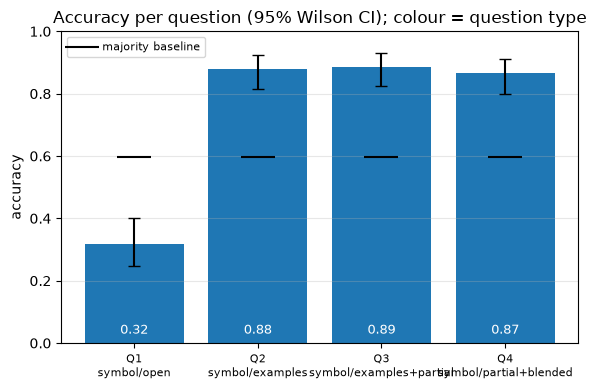

> **Result:** The most accurate question is Q3 (0.89, 95% CI 0.82–0.93), the least accurate Q1 (0.32). DK answers play no role (below 5% for every question). Q1 is not better than always giving the most frequent expected answer (baseline 0.60). 

In [45]:
acc = U.show_accuracy(run)

## 5.4 Accuracy per image group
The same accuracy for each image group: a low value shows which kind of image makes a question fail.

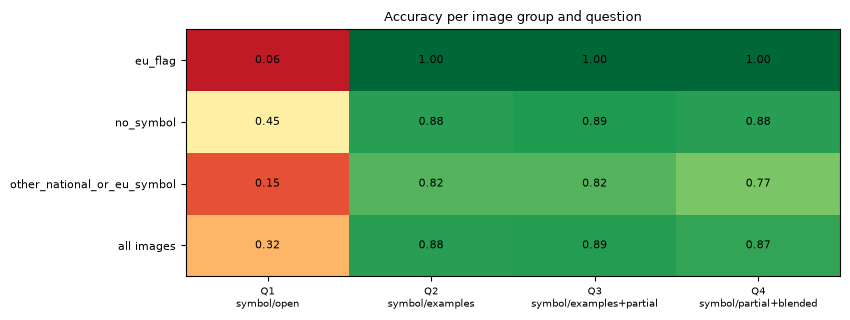

> **Result:** The weakest combinations are eu_flag with Q1 (0.06) and other_national_or_eu_symbol with Q1 (0.15). 

In [46]:
U.show_groups(run, acc)

## 5.5 Hardest images
The images with the largest share of wrong answers. For each image: the image, the answer generated for every question (`read as` = the normalised answer that is scored), the expected answer, and which answers are wrong. Errors on every question point to a hard image or a questionable label; errors on some questions point to the wording.

9 of 141 scored images have at least 100% wrong answers; the 6 hardest are shown (all in comparison_results/question_accuracy_single_model/image_difficulty.csv).


### `503133.jpeg`  
label: **1**  |  group: other_national_or_eu_symbol  |  folder: natl_eu_flags  |  **4 of 4 answers wrong**

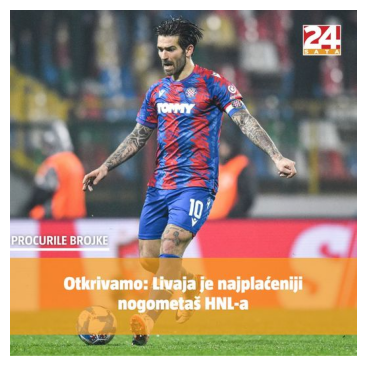

,question,generated answer,read as,expected,
Q1,symbol/open,EU,unparsed,yes,✗ wrong
Q2,symbol/examples,No,no,yes,✗ wrong
Q3,symbol/examples+partial,No,no,yes,✗ wrong
Q4,symbol/partial+blended,No,no,yes,✗ wrong


> **Result:** Wrong answers: Q1 ("unparsed" instead of "yes"), Q2 ("no" instead of "yes"), Q3 ("no" instead of "yes") and Q4 ("no" instead of "yes").

### `506247.jpeg`  
label: **0**  |  group: no_symbol  |  folder: no_natl_eu_flags  |  **4 of 4 answers wrong**

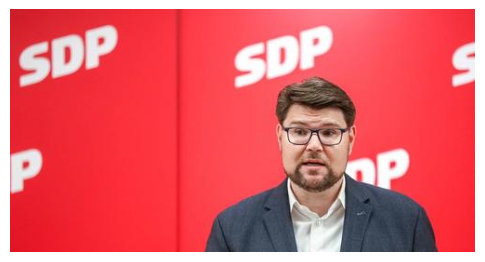

,question,generated answer,read as,expected,
Q1,symbol/open,National,unparsed,no,✗ wrong
Q2,symbol/examples,National,unparsed,no,✗ wrong
Q3,symbol/examples+partial,Yes,yes,no,✗ wrong
Q4,symbol/partial+blended,Yes,yes,no,✗ wrong


> **Result:** Wrong answers: Q1 ("unparsed" instead of "no"), Q2 ("unparsed" instead of "no"), Q3 ("yes" instead of "no") and Q4 ("yes" instead of "no").

### `518278.jpeg`  
label: **1**  |  group: other_national_or_eu_symbol  |  folder: natl_eu_flags  |  **4 of 4 answers wrong**

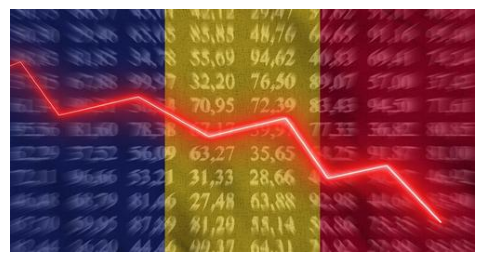

,question,generated answer,read as,expected,
Q1,symbol/open,EU,unparsed,yes,✗ wrong
Q2,symbol/examples,No.,no,yes,✗ wrong
Q3,symbol/examples+partial,No,no,yes,✗ wrong
Q4,symbol/partial+blended,No,no,yes,✗ wrong


> **Result:** Wrong answers: Q1 ("unparsed" instead of "yes"), Q2 ("no" instead of "yes"), Q3 ("no" instead of "yes") and Q4 ("no" instead of "yes").

### `519156.jpeg`  
label: **0**  |  group: no_symbol  |  folder: no_natl_eu_flags  |  **4 of 4 answers wrong**

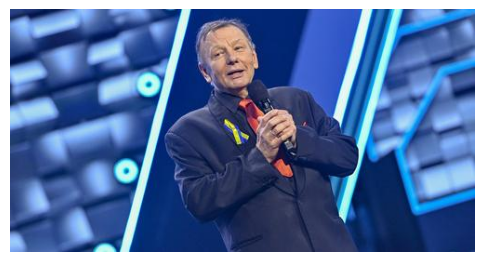

,question,generated answer,read as,expected,
Q1,symbol/open,Yes,yes,no,✗ wrong
Q2,symbol/examples,Yes,yes,no,✗ wrong
Q3,symbol/examples+partial,Yes,yes,no,✗ wrong
Q4,symbol/partial+blended,Yes,yes,no,✗ wrong


> **Result:** Wrong answers: Q1 ("yes" instead of "no"), Q2 ("yes" instead of "no"), Q3 ("yes" instead of "no") and Q4 ("yes" instead of "no").

### `521884.jpeg`  
label: **0**  |  group: no_symbol  |  folder: no_natl_eu_flags  |  **4 of 4 answers wrong**

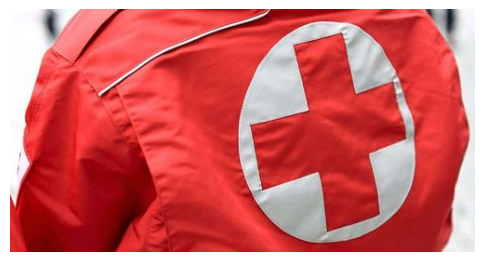

,question,generated answer,read as,expected,
Q1,symbol/open,National,unparsed,no,✗ wrong
Q2,symbol/examples,National flag,yes,no,✗ wrong
Q3,symbol/examples+partial,National,unparsed,no,✗ wrong
Q4,symbol/partial+blended,Yes,yes,no,✗ wrong


> **Result:** Wrong answers: Q1 ("unparsed" instead of "no"), Q2 ("yes" instead of "no"), Q3 ("unparsed" instead of "no") and Q4 ("yes" instead of "no").

### `531641.jpeg`  
label: **0**  |  group: no_symbol  |  folder: no_natl_eu_flags  |  **4 of 4 answers wrong**

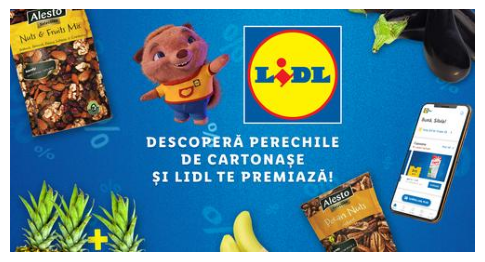

,question,generated answer,read as,expected,
Q1,symbol/open,EU,unparsed,no,✗ wrong
Q2,symbol/examples,Yes,yes,no,✗ wrong
Q3,symbol/examples+partial,Yes,yes,no,✗ wrong
Q4,symbol/partial+blended,Yes,yes,no,✗ wrong


> **Result:** Wrong answers: Q1 ("unparsed" instead of "no"), Q2 ("yes" instead of "no"), Q3 ("yes" instead of "no") and Q4 ("yes" instead of "no").

In [47]:
U.show_hardest_images(run, n=6)  # n = number of images shown